# 02 · Channel-breakout momentum on the ASX 500

**Goal (project brief):** find a profitable momentum strategy and report returns, volatility, Sharpe, max drawdown and alpha/beta. The brief's crypto universe is replaced with Australian equities. The strategy studied is the **Donchian channel breakout**.

Run `01_data_and_universe.ipynb` first; it writes `data/clean.pkl`.

**Research discipline.** Every design choice (channel length, exit, filters, execution timing, weighting) is made on **2006–2016 (in-sample, IS)**. **2017–2026 (out-of-sample, OOS)** is run once as the check.

In [37]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
TRADING_DAYS = 252
IS, OOS = slice("2006-01-01", "2016-12-31"), slice("2017-01-01", None)

# chart colours (validated categorical palette, fixed order)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a8a"
BLUE_LIGHT, BLUE_MID = "#cde2fb", "#86b6ef"

## Import Data

In [38]:
df = pd.read_pickle("data/clean.pkl")
axjo = df["bench_ret"]["^AXJO"]
print(f"{df['adj'].shape[1]} stocks, {df['adj'].index[0]:%Y-%m-%df} to {df['adj'].index[-1]:%Y-%m-%df}")

1628 stocks, 2005-01-04f to 2026-10-01f


## 1. Signal: Donchian channel breakout

The rules are those of the classic "Turtle" system:

| | Entry | Exit |
|---|---|---|
| Long | close > highest high of the prior **N** days | close < lowest low of the prior **M** days |
| Short | close < lowest low of the prior **N** days | close > highest high of the prior **M** days |

* The channels exclude today (`shift(1)`), so a breakout means today's close is beyond every high or low of the window.
* The position is *stateful*: it stays on until the exit fires, not just on the breakout day.
* M defaults to N/2, a tighter exit channel than entry channel.
* A position is forced flat when the stock leaves the universe.
* Optional activity filter: keep only entries where breakout-day volume is more than 1.5× its 50-day average.

In [39]:
def channels(df, n):
    # upper/lower channel over the n days *before* t
    upper = df["high"].rolling(n, min_periods=n).max().shift(1)
    lower = df["low"].rolling(n, min_periods=n).min().shift(1)
    return upper, lower


def donchian_state(df, n, m=None, vol_filter=None):
    # +1 long, -1 short, 0 flat, per stock per day
    m = m or max(n // 2, 2)
    px = df["adj"]
    up_n, lo_n = channels(df, n)
    up_m, lo_m = channels(df, m)
    long_in, short_in = px > up_n, px < lo_n
    if vol_filter:
        rel = df["volume"] / df["volume"].rolling(50, min_periods=30).mean().shift(1)
        keep = rel > 1.5 if vol_filter == "high" else rel <= 1.5
        long_in, short_in = long_in & keep, short_in & keep
    member = df["member"]

    def state(enter, leave):
        s = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
        s = s.mask(leave | ~member, 0.0).mask(enter & member, 1.0)
        return s.ffill().fillna(0.0)

    return state(long_in, px < lo_m) - state(short_in, px > up_m)

## 2. Backtest engine

**Portfolio.** The long side holds +0.5 of capital and the short side −0.5: dollar neutral, gross exposure 1. A long-only variant puts 1.0 on the long side.

**Holdings drift.** A new entry gets an equal share of its side (side gross ÷ names on that side), and the rest of that side is scaled down pro rata to make room. After that, positions **drift with price**; they are not reset to equal weight every day. Every trade is charged, including the pro-rata scaling.

**Why not reset to equal weight daily?** An earlier version did, charging only for changes in target weights. On ASX closing prices that daily reset quietly harvests bid-ask bounce and stale-price reversal in small caps. Section 12 shows the size of this: *random* stocks reset daily earn a Sharpe of about 2. The drift engine avoids it, and the first check below shows it reproduces a static buy-and-hold portfolio exactly.

**Timing.** A signal formed at day *t*'s close is traded at day *t+1*'s close (`lag=2`, the default) and earns returns from *t+2*. `lag=1` trades at the signal close itself, for comparison.

**Costs.** 20 bps per unit of one-way turnover (market orders, per the brief); 7 bps (limit orders) and 50 bps are sensitivities.

In [40]:
def backtest_drift(signal, df, scheme="neutral", cost_bps=20, lag=2, scale=None):
    sig = np.sign(signal.shift(lag - 1).fillna(0.0)).values if lag > 1 else np.sign(signal.fillna(0.0)).values
    r = df["ret"].reindex_like(signal).fillna(0.0).values
    k = np.ones(len(sig)) if scale is None else scale.reindex(signal.index).fillna(0.0).values
    sides = [(1, 0.5), (-1, 0.5)] if scheme == "neutral" else [(1, 1.0)]
    h = np.zeros(sig.shape[1])                     # current weights (fraction of NAV)
    gross, turn = np.zeros(len(sig)), np.zeros(len(sig))
    for t in range(len(sig)):
        if t:
            pnl = h @ r[t]
            gross[t] = pnl
            h = h * (1 + r[t]) / (1 + pnl)          # drift
        new = np.zeros_like(h)
        for side, g in sides:
            g = g * k[t]
            on = sig[t] == side
            if not on.any() or g == 0:
                continue
            keep = on & (np.sign(h) == side) & (h != 0)
            enter = on & ~keep
            w_enter = g / on.sum()
            rest = g - w_enter * enter.sum()
            held = np.abs(h[keep]).sum()
            new[enter] = side * w_enter
            if keep.any():
                new[keep] = h[keep] * (rest / held if held > 0 else 0) #updating the holding weights
        turn[t] = np.abs(new - h).sum()
        h = new
    gross, turn = pd.Series(gross, signal.index), pd.Series(turn, signal.index)
    return pd.DataFrame({"gross": gross, "net": gross - turn * cost_bps / 1e4, "turnover": turn})


def stats(r, bench=None):
    r = r.dropna()
    ann_ret, ann_vol = r.mean() * TRADING_DAYS, r.std() * np.sqrt(TRADING_DAYS)
    eq = (1 + r).cumprod()
    out = {"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol,
           "max_dd": (eq / eq.cummax() - 1).min()}
    if bench is not None:
        b = bench.reindex(r.index).fillna(0.0)
        fit = sm.OLS(r, sm.add_constant(b)).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        out.update(alpha=fit.params["const"] * TRADING_DAYS, alpha_t=fit.tvalues["const"], beta=fit.params.iloc[1])
    return pd.Series(out)


def report(bts, bench, periods=(("IS", IS), ("OOS", OOS))):
    # one row per (strategy, period); bts = {name: backtest frame}
    rows = {}
    for name, bt in bts.items():
        for per, sl in periods:
            s = stats(bt["net"].loc[sl], bench)
            s["turnover"] = bt["turnover"].loc[sl].mean()
            rows[(name, per)] = s
    return pd.DataFrame(rows).T

**Engine check.** Hold 171 random stocks from 2006 with no further trades. The drift engine must match a hand-computed buy-and-hold exactly, with zero turnover after day one.

In [41]:
rng = np.random.default_rng(1)
start = "2006-01-03"
pool = df["member"].loc[start:].iloc[0]
pick = rng.choice(pool[pool].index, 171, replace=False)
static = pd.DataFrame(0.0, index=df["ret"].index, columns=df["ret"].columns)
static.loc[start:, pick] = 1
bt = backtest_drift(static, df, "long", cost_bps=0, lag=1).loc["2006-01-04":]
true_bh = (1 + df["ret"][pick].fillna(0).loc["2006-01-04":]).cumprod().mean(axis=1).iloc[-1]
print(f"drift engine: {(1 + bt['net']).prod():.4f}   true buy-and-hold: {true_bh:.4f}   "
      f"turnover after day 1: {bt['turnover'].iloc[1:].sum():.6f}")

drift engine: 4.6027   true buy-and-hold: 4.6027   turnover after day 1: 0.000000


## 3. Benchmarks

* **ASX 200 (^AXJO):** investable, cap-weighted, used for beta.
* **Equal-weight ASX 500, drifting:** built with the same engine. Members are held with drifting weights, joiners enter at the average weight, and leavers exit. It has the **same survivorship bias** as the strategy, so alpha measured against it removes the common component.

In [42]:
ew = backtest_drift(df["member"].astype(float), df, "long", cost_bps=0, lag=1)["net"]
bench_table = pd.DataFrame({
    ("EW ASX 500", period): stats(ew.loc[sl], axjo) for period, sl in [("IS", IS), ("OOS", OOS)]
} | {("ASX 200", period): stats(axjo.loc[sl]) for period, sl in [("IS", IS), ("OOS", OOS)]}).T
bench_table.to_csv(RESULTS / "01_benchmark.csv")
bench_table

alpha  alpha_t  ann_ret  ann_vol  beta  max_dd  sharpe
EW ASX 500 IS   0.037    0.789    0.060    0.183 0.775  -0.683   0.326
           OOS  0.045    0.950    0.101    0.207 1.000  -0.458   0.486
ASX 200    IS     NaN      NaN    0.030    0.182   NaN  -0.539   0.164
           OOS    NaN      NaN    0.056    0.148   NaN  -0.365   0.380

## 4. Time horizon: reversal at short horizons, momentum at long ones

The brief's first hypothesis is that short horizons produce reversal and long horizons produce momentum. Channel lengths from 5 to 400 days are swept, each traded at the signal close (`lag=1`) and at the next close (`lag=2`).

In [44]:
rows = {}
for n in [5, 10, 20, 50, 100, 150, 200, 250, 300, 400]:
    s = donchian_state(df, n)
    for lag in [1, 2]:
        bt = backtest_drift(s, df, "neutral", 20, lag)
        for per, sl in [("IS", IS), ("OOS", OOS)]:
            st = stats(bt["net"].loc[sl], ew)
            st["gross_sharpe"] = stats(bt["gross"].loc[sl])["sharpe"]
            st["turnover"] = bt["turnover"].loc[sl].mean()
            rows[(n, lag, per)] = st
horizon = pd.DataFrame(rows).T.rename_axis(["N", "lag", "period"])
horizon.to_csv(RESULTS / "02_horizon_sweep.csv")
horizon["sharpe"].unstack(["lag", "period"]).round(2)

lag          1             2       
period      IS    OOS     IS    OOS
N                                  
5      -14.030 -8.050 -7.840 -4.040
10      -8.650 -4.330 -5.110 -1.950
20      -4.900 -2.040 -2.830 -0.600
50      -1.590 -0.380 -0.490  0.230
100     -0.020  0.550  0.680  0.880
150      0.580  0.980  1.070  1.200
200      0.790  1.270  1.200  1.460
250      1.080  1.380  1.510  1.500
300      0.760  1.280  1.020  1.370
400      0.760  1.120  1.050  1.210

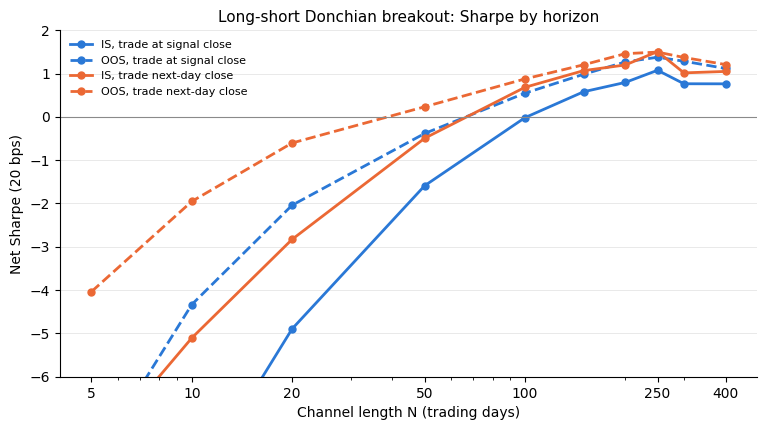

In [45]:
fig, ax = plt.subplots(figsize=(9, 4.5))
styles = {(1, "IS"): (BLUE, "-"), (1, "OOS"): (BLUE, "--"), (2, "IS"): (ORANGE, "-"), (2, "OOS"): (ORANGE, "--")}
for (lag, per), (c, ls) in styles.items():
    g = horizon.xs((lag, per), level=("lag", "period"))["sharpe"]
    ax.plot(g.index, g.values, color=c, ls=ls, marker="o", ms=5, lw=2,
            label=f"{per}, trade {'at signal' if lag == 1 else 'next-day'} close")
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100, 250, 400], labels=[5, 10, 20, 50, 100, 250, 400])
ax.set_ylim(-6, 2)
ax.set_xlabel("Channel length N (trading days)")
ax.set_ylabel("Net Sharpe (20 bps)")
ax.set_title("Long-short Donchian breakout: Sharpe by horizon", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False)
fig.savefig(RESULTS / "horizon_sweep.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading the sweep**
* **N ≤ 50 days: reversal.** Breakouts lose money, strongly so at N=5. Much of this is bid-ask bounce: a breakout close is often an ask-side print, so the "breakout" partly reverses the next day. Closing prices overstate the reversal, so running the trade the other way is not free money.
* **N ≥ 100 days: momentum.** Sharpe rises to a broad plateau between 150 and 400 days, peaking around **N=250** (about one year) on IS. The plateau means the choice is not knife-edge.
* **Execution matters.** Trading one day later (orange) beats trading at the breakout close (blue) at every horizon. Don't chase the breakout print: wait a day or work a limit order.

## 5. Exit channel (IS only)

In [46]:
exit_grid = {}
for n in [150, 200, 250, 300]:
    for ratio in [0.25, 0.5, 1.0]:
        m = int(n * ratio)
        bt = backtest_drift(donchian_state(df, n, m), df, "neutral", 20, 2)
        exit_grid[(n, m)] = stats(bt["net"].loc[IS], ew)
exit_grid = pd.DataFrame(exit_grid).T.rename_axis(["N", "M"])
exit_grid.to_csv(RESULTS / "03_exit_grid_IS.csv")
exit_grid["sharpe"].unstack().round(2)

M,37,50,62,75,100,125,150,200,250,300
N,,,,,,,,,,
150,0.510,NaN,NaN,1.070,NaN,NaN,1.110,NaN,NaN,NaN
200,NaN,0.860,NaN,NaN,1.200,NaN,NaN,1.250,NaN,NaN
250,NaN,NaN,1.280,NaN,NaN,1.510,NaN,NaN,1.400,NaN
300,NaN,NaN,NaN,1.110,NaN,NaN,1.020,NaN,NaN,1.110


**N=250, M=125** has the best IS Sharpe. A tight exit (M=N/4) churns too much, and M=N gives back too much before exiting. This spec is fixed from here on.

## 6. Activity: are high-volume breakouts stronger?

The brief suggests that moves with heavy activity and new information carry more momentum. Entries are split by breakout-day volume relative to its 50-day average.

In [48]:
N, M = 250, 125
vol_bts = {f"volume = {vf or 'any'}": backtest_drift(donchian_state(df, N, M, vol_filter=vf), df, "neutral", 20, 2)
           for vf in [None, "high", "low"]}
vol_table = report(vol_bts, ew)
vol_table.to_csv(RESULTS / "04_volume_filter.csv")
vol_table[["sharpe", "alpha", "alpha_t"]]

sharpe  alpha  alpha_t
volume = any  IS    1.507  0.101    4.388
              OOS   1.495  0.092    4.112
volume = high IS    1.460  0.107    4.319
              OOS   1.489  0.097    4.098
volume = low  IS    1.398  0.103    4.097
              OOS   1.341  0.088    3.779

High-volume breakouts beat low-volume ones, which is the direction the brief predicts. They do **not** beat simply taking every breakout on IS, so the filter is not used. (Under the old daily-reset engine the filter looked mildly helpful; that disappeared once holdings drift.)

## 7. Final strategy and variants

Final spec: **N=250 entry, M=125 exit, all breakouts, next-day execution, 20 bps.**

| Variant | Description |
|---|---|
| Research L/S | longs and shorts across all 500 names |
| **Implementable L/S** | longs across the ASX 500, **shorts only in the 200 most liquid names**. ASX short selling is limited to approved, liquid securities. |
| Implementable, 10% vol target | same book scaled to 10% annualised vol using trailing 63-day realised vol (known at *t*, capped at 3×) |
| Long-only | breakout longs only, 100% invested |

In [49]:
s = donchian_state(df, N, M)
rank = df["adv"].where(df["member"]).rank(axis=1, ascending=False)
top200 = (rank <= 200).shift(1, fill_value=False)
s_impl = s.where((s > 0) | top200, 0.0)

bts = {
    "Research L/S (all 500)": backtest_drift(s, df, "neutral", 20, 2),
    "Implementable L/S (shorts top 200)": backtest_drift(s_impl, df, "neutral", 20, 2),
    "Long-only": backtest_drift(s, df, "long", 20, 2),
}
r_impl = bts["Implementable L/S (shorts top 200)"]["net"]
scale = (0.10 / (r_impl.rolling(63).std() * np.sqrt(TRADING_DAYS))).shift(1).clip(upper=3).fillna(0)
bts["Implementable, 10% vol target"] = backtest_drift(s_impl, df, "neutral", 20, 2, scale=scale)

periods = (("IS", IS), ("OOS", OOS), ("FULL", slice("2006-01-01", None)))
final = report(bts, ew, periods)
vs_axjo = report(bts, axjo, periods)[["alpha", "alpha_t", "beta"]].add_suffix("_axjo")
final = final.join(vs_axjo)
final.to_csv(RESULTS / "05_final_strategies.csv")
final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta", "alpha_axjo", "beta_axjo", "turnover"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  beta  alpha_axjo  beta_axjo  turnover
Research L/S (all 500)             IS      0.105    0.070   1.507  -0.182  0.101    4.388 0.058       0.104      0.025     0.025
                                   OOS     0.103    0.069   1.495  -0.086  0.092    4.112 0.105       0.102      0.023     0.023
                                   FULL    0.104    0.069   1.502  -0.182  0.097    6.002 0.083       0.103      0.024     0.024
Implementable L/S (shorts top 200) IS      0.094    0.079   1.194  -0.205  0.093    3.453 0.018       0.096     -0.079     0.033
                                   OOS     0.063    0.082   0.763  -0.115  0.054    2.172 0.091       0.067     -0.084     0.028
                                   FULL    0.079    0.080   0.987  -0.205  0.075    4.057 0.057       0.083     -0.081     0.030
Long-only                          IS      0.146    0.184   0.796  -0.603  0.092    3.804 0.911       0.125      0.708     0.017
                                   OOS     0.193    0.196   0.983  -0.441  0.102    5.421 0.902       0.141      0.928     0.014
                                   FULL    0.168    0.190   0.887  -0.603  0.097    6.202 0.906       0.135      0.790     0.015
Implementable, 10% vol target      IS      0.122    0.107   1.139  -0.234  0.120    3.307 0.039       0.125     -0.090     0.055
                                   OOS     0.079    0.106   0.750  -0.173  0.069    2.122 0.100       0.085     -0.103     0.051
                                   FULL    0.102    0.107   0.957  -0.234  0.096    3.913 0.071       0.106     -0.095     0.053

`alpha` and `beta` are measured against the equal-weight ASX 500; the `_axjo` columns are against the ASX 200. Alpha is annualised, with Newey-West (10-lag) t-stats.

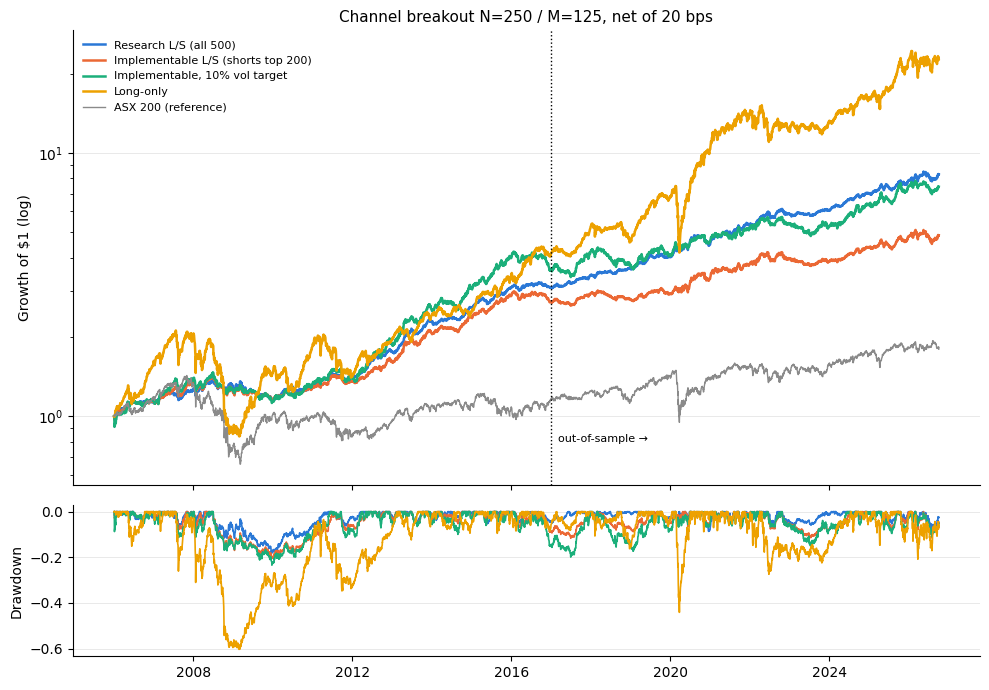

In [51]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for (name, c) in zip(["Research L/S (all 500)", "Implementable L/S (shorts top 200)", "Implementable, 10% vol target","Long-only"],
                     [BLUE, ORANGE, AQUA,YELLOW]):
    eq = (1 + bts[name]["net"].loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=1.8, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
axs[0].plot((1 + axjo.loc["2006":].fillna(0)).cumprod(), color=GREY, lw=1, label="ASX 200 (reference)")
axs[0].axvline(pd.Timestamp("2017-01-01"), color="k", ls=":", lw=1)
axs[0].text(pd.Timestamp("2017-03-01"), 0.8, "out-of-sample →", fontsize=8)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title("Channel breakout N=250 / M=125, net of 20 bps", fontsize=11)
axs[0].legend(fontsize=8, frameon=False)
axs[1].set_ylabel("Drawdown")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "equity_curves.png", dpi=130)
plt.show()

## 8. Execution and costs

Implementable L/S book, by cost level and by execution timing.

In [52]:
cost_bts = {f"{c} bps, {'signal' if lag == 1 else 'next-day'} close": backtest_drift(s_impl, df, "neutral", c, lag)
            for c in [0, 7, 20, 50] for lag in [1, 2]}
costs = report(cost_bts, ew)
costs.to_csv(RESULTS / "06_costs.csv")
costs[["sharpe", "alpha", "alpha_t"]].unstack().reindex(list(cost_bts)).round(3)

sharpe       alpha       alpha_t      
                           IS   OOS    IS   OOS      IS   OOS
0 bps, signal close     1.294 0.911 0.101 0.066   3.773 2.652
0 bps, next-day close   1.405 0.934 0.109 0.068   4.081 2.735
7 bps, signal close     1.220 0.852 0.095 0.061   3.553 2.457
7 bps, next-day close   1.331 0.874 0.104 0.063   3.861 2.538
20 bps, signal close    1.084 0.742 0.084 0.052   3.145 2.094
20 bps, next-day close  1.194 0.763 0.093 0.054   3.453 2.172
50 bps, signal close    0.771 0.488 0.060 0.031   2.212 1.251
50 bps, next-day close  0.878 0.506 0.068 0.032   2.515 1.322

Turnover is low (about 3% of gross a day) because a 250-day channel trades rarely, so the edge survives limit-order and market-order costs. At 50 bps, realistic for the smallest names, OOS alpha is no longer statistically significant.

## 9. Legs and calendar years

In [53]:
legs = {"L/S strategy": r_impl,
        "long leg": backtest_drift(s_impl.clip(lower=0), df, "neutral", 20, 2)["net"],
        "short leg": backtest_drift(s_impl.clip(upper=0), df, "neutral", 20, 2)["net"],
        "EW ASX 500": ew, "ASX 200": axjo}
yearly = pd.DataFrame(legs).loc["2006":].fillna(0)
yearly = yearly.groupby(yearly.index.year).apply(lambda x: (1 + x).prod() - 1)
yearly.to_csv(RESULTS / "07_yearly.csv")
full_years = yearly.loc[:2025, "L/S strategy"]
print(f"positive full years: {(full_years > 0).sum()} of {len(full_years)}")
yearly.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4, subset=["L/S strategy", "long leg", "short leg"])

positive full years: 15 of 20


,L/S strategy,long leg,short leg,EW ASX 500,ASX 200
date,,,,,
2006,15.1%,26.7%,-9.4%,46.7%,18.7%
2007,15.4%,13.3%,1.3%,23.2%,11.8%
2008,-7.4%,-33.3%,36.3%,-62.3%,-41.3%
2009,-5.7%,29.9%,-27.8%,88.9%,30.8%
2010,11.1%,12.7%,-2.0%,23.9%,-2.6%
2011,5.4%,-12.2%,18.6%,-28.1%,-15.8%
2012,19.2%,17.6%,1.0%,1.8%,14.4%
2013,27.3%,11.8%,13.5%,1.4%,15.1%
2014,15.1%,1.3%,13.4%,-8.9%,0.4%


* **2009 is the textbook momentum crash.** Beaten-down stocks rebounded hard and the short leg lost heavily; the long leg partly offset it.
* The **long leg** earns in trending bull years. The **short leg** pays in bear years (2008, 2011, 2014, 2022), so the two legs diversify each other.

## 10. Size control

The implementable book is long small caps and short large caps, so some of its alpha could be a size tilt. A second factor is added: EW ASX 500 minus EW top 200, both drifting.

In [54]:
ew200 = backtest_drift((df["member"] & top200).astype(float), df, "long", cost_bps=0, lag=1)["net"]
factors = pd.DataFrame({"ew_asx500": ew, "size": ew - ew200})
rows = {}
for name in ["Research L/S (all 500)", "Implementable L/S (shorts top 200)"]:
    for per, sl in [("IS", IS), ("OOS", OOS)]:
        fit = sm.OLS(bts[name]["net"].loc[sl], sm.add_constant(factors.loc[sl].fillna(0))).fit(
            cov_type="HAC", cov_kwds={"maxlags": 10})
        rows[(name, per)] = {"alpha": fit.params["const"] * TRADING_DAYS, "alpha_t": fit.tvalues["const"],
                             "beta_ew": fit.params["ew_asx500"], "beta_size": fit.params["size"]}
size_ctrl = pd.DataFrame(rows).T
size_ctrl.to_csv(RESULTS / "09_size_control.csv")
size_ctrl

alpha  alpha_t  beta_ew  beta_size
Research L/S (all 500)             IS   0.098    4.379    0.051     -0.166
                                   OOS  0.094    4.178    0.092      0.107
Implementable L/S (shorts top 200) IS   0.097    3.599    0.029      0.257
                                   OOS  0.061    2.566    0.042      0.409

The implementable book does load on size, more so out-of-sample, but alpha stays significant after controlling for it.

## 11. Liquidity / capacity

In [55]:
held_adv = (df["adv"].where(s_impl != 0).median(axis=1) / 1e6).loc["2006":]
liq = held_adv.groupby(held_adv.index.year).median().rename("median traded value of held names, A$m/day")
liq.to_csv(RESULTS / "08_liquidity.csv")
liq.to_frame().T.round(2)

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"median traded value of held names, A$m/day",0.130,0.200,0.490,0.230,0.190,0.320,0.510,0.640,0.410,0.540,...,0.510,0.750,1.500,3.490,1.540,4.130,3.720,2.900,3.130,5.620


The median held stock traded well under A$1m a day before 2019. This is a small-capital strategy, and 20 bps is optimistic for the thinnest names.

## 12. Monte Carlo: strategy vs random buy-and-hold

**Question:** is the strategy better than just buying a random basket of ASX 500 stocks and holding it?

**Setup**
* Each simulation picks **K** stocks at random from the ASX 500 members on the start date, buys them equal weight (20 bps once), and holds them to the end with no rebalancing.
* 1,000 simulations for each K: K=30 (a typical concentrated investor) and K = the strategy's average number of longs.
* Two windows: full sample (2006–) and OOS (2017–).
* Random picks come from stocks still listed today, the **same survivorship bias** as the strategy.

**Control.** The same random picks are also reset to equal weight **every day**, with no costs. This is the construction the first backtest effectively used. It is not investable, and it measures how much daily resetting on closing prices inflates results.

In [56]:
def metrics(r, bench):
    # vectorised annual metrics for a days x portfolios matrix
    r = np.asarray(r)
    r = r[:, None] if r.ndim == 1 else r
    eq = np.cumprod(1 + r, axis=0)
    b = np.asarray(bench)
    bc = b - b.mean()
    beta = (bc[:, None] * (r - r.mean(0))).sum(0) / (bc ** 2).sum()
    vol = r.std(0, ddof=1) * np.sqrt(TRADING_DAYS)
    return pd.DataFrame({
        "cagr": eq[-1] ** (TRADING_DAYS / len(r)) - 1,
        "ann_vol": vol,
        "sharpe": r.mean(0) * TRADING_DAYS / vol,
        "max_dd": (eq / np.maximum.accumulate(eq, axis=0) - 1).min(0),
        "alpha_axjo": (r.mean(0) - beta * b.mean()) * TRADING_DAYS,
        "beta_axjo": beta,
    })


N_SIMS, COST = 1000, 20e-4
WINDOWS = {"FULL 2006-": "2006-01-03", "OOS 2017-": "2017-01-03"}
k_match = int(round((s > 0).sum(axis=1).loc["2006":].mean()))
mc_strats = {"Long-only breakout": bts["Long-only"]["net"],
             "L/S implementable": r_impl,
             "L/S, 10% vol target": bts["Implementable, 10% vol target"]["net"]}
ret0, axjo0 = df["ret"].fillna(0.0), axjo.fillna(0.0)
rng = np.random.default_rng(7)

rows, dists, fans = [], {}, {}
for wname, start in WINDOWS.items():
    r_win, b_win = ret0.loc[start:], axjo0.loc[start:]
    pool = np.flatnonzero(df["member"].loc[start:].iloc[0].values)
    growth = np.cumprod(1 + r_win.values, axis=0)
    for k in [30, k_match]:
        picks = np.array([rng.choice(pool, size=k, replace=False) for _ in range(N_SIMS)])
        value = growth[:, picks].mean(axis=2) * (1 - COST)          # buy and hold, weights drift
        daily = np.vstack([value[:1] - 1, value[1:] / value[:-1] - 1])
        dists[(wname, k)], fans[(wname, k)] = metrics(daily, b_win), value
        reset = metrics(r_win.values[:, picks].mean(axis=2), b_win)  # control: daily reset to equal weight
        for label, m in [(f"random B&H, K={k}", dists[(wname, k)]), (f"control: daily-reset EW, K={k}", reset)]:
            for q, row in m.quantile([0.05, 0.5, 0.95]).iterrows():
                rows.append({"window": wname, "portfolio": label, "stat": f"p{int(q * 100)}", **row})
    for sname, sr in mc_strats.items():
        ms = metrics(sr.loc[start:].values, b_win).iloc[0]
        rows.append({"window": wname, "portfolio": sname, "stat": "value", **ms})
        for k in [30, k_match]:
            rows.append({"window": wname, "portfolio": sname, "stat": f"percentile vs K={k}",
                         **{c: (dists[(wname, k)][c] < ms[c]).mean() * 100 for c in ["cagr", "sharpe", "max_dd", "alpha_axjo"]}})

mc = pd.DataFrame(rows)
mc.to_csv(RESULTS / "10_mc_buyhold.csv", index=False)
print(f"K matched to the strategy's average long count: {k_match}")
mc[mc["window"] == "OOS 2017-"].drop(columns="window").set_index(["portfolio", "stat"])

K matched to the strategy's average long count: 187


cagr  ann_vol  sharpe  max_dd  alpha_axjo  beta_axjo
portfolio                      stat                                                                       
random B&H, K=30               p5                    0.023    0.174   0.214  -0.587      -0.003      0.764
                               p50                   0.084    0.211   0.485  -0.474       0.053      0.910
                               p95                   0.143    0.270   0.734  -0.390       0.108      1.050
control: daily-reset EW, K=30  p5                    0.148    0.167   0.863  -0.495       0.112      0.619
                               p50                   0.212    0.188   1.123  -0.430       0.170      0.727
                               p95                   0.288    0.210   1.372  -0.372       0.234      0.833
random B&H, K=187              p5                    0.068    0.163   0.471  -0.461       0.030      0.873
                               p50                   0.089    0.175   0.576  -0.434       0.050      0.921
                               p95                   0.110    0.188   0.683  -0.408       0.068      0.971
control: daily-reset EW, K=187 p5                    0.197    0.137   1.337  -0.440       0.149      0.692
                               p50                   0.223    0.143   1.484  -0.420       0.171      0.727
                               p95                   0.248    0.148   1.622  -0.398       0.192      0.762
Long-only breakout             value                 0.189    0.196   0.983  -0.441       0.141      0.928
                               percentile vs K=30   99.800      NaN  99.900  74.400      99.600        NaN
                               percentile vs K=187 100.000      NaN 100.000  33.000     100.000        NaN
L/S implementable              value                 0.061    0.082   0.763  -0.115       0.067     -0.084
                               percentile vs K=30   25.300      NaN  96.600 100.000      66.800        NaN
                               percentile vs K=187   1.100      NaN 100.000 100.000      94.000        NaN
L/S, 10% vol target            value                 0.077    0.106   0.750  -0.173       0.085     -0.103
                               percentile vs K=30   42.400      NaN  95.900 100.000      81.900        NaN
                               percentile vs K=187  14.900      NaN  99.900 100.000     100.000        NaN

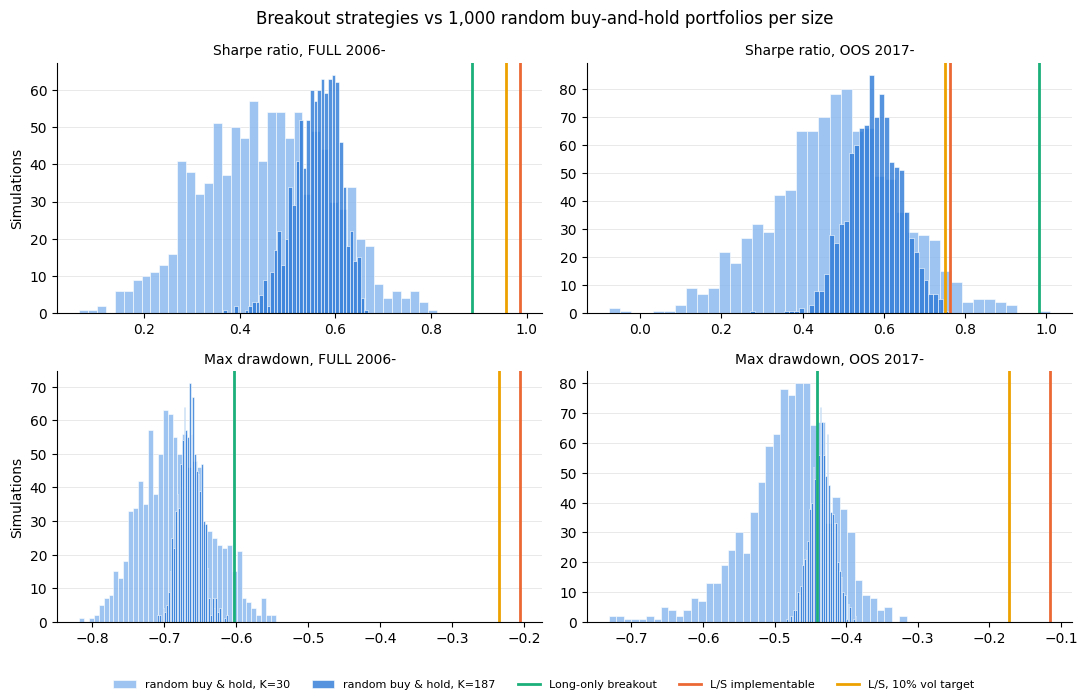

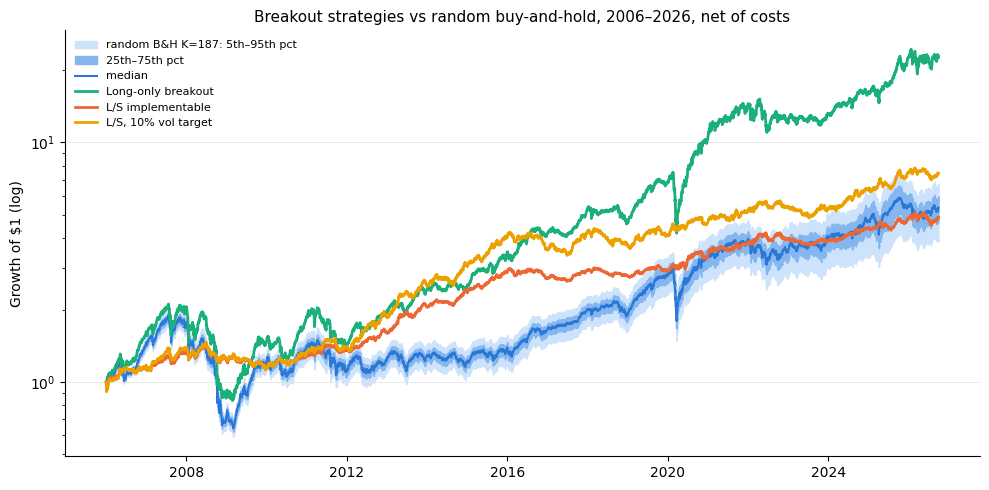

In [57]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for i, wname in enumerate(WINDOWS):
    for j, (col, label) in enumerate([("sharpe", "Sharpe ratio"), ("max_dd", "Max drawdown")]):
        ax = axs[j, i]
        for k, c in [(30, BLUE_MID), (k_match, BLUE)]:
            ax.hist(dists[(wname, k)][col], bins=40, color=c, alpha=0.8, edgecolor="white", linewidth=0.5,
                    label=f"random buy & hold, K={k}")
        for (sname, sr), c in zip(mc_strats.items(), [AQUA, ORANGE, YELLOW]):
            ax.axvline(metrics(sr.loc[WINDOWS[wname]:].values, axjo0.loc[WINDOWS[wname]:]).iloc[0][col],
                       color=c, lw=2, label=sname)
        ax.set_title(f"{label}, {wname}", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e5e5e5", lw=0.6)
        ax.set_axisbelow(True)
axs[0, 0].set_ylabel("Simulations")
axs[1, 0].set_ylabel("Simulations")
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.suptitle(f"Breakout strategies vs {N_SIMS:,} random buy-and-hold portfolios per size", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(RESULTS / "mc_distributions.png", dpi=130)
plt.show()

value = fans[("FULL 2006-", k_match)]
idx = ret0.loc[WINDOWS["FULL 2006-"]:].index
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(idx, np.percentile(value, 5, axis=1), np.percentile(value, 95, axis=1), color=BLUE_LIGHT,
                label=f"random B&H K={k_match}: 5th–95th pct")
ax.fill_between(idx, np.percentile(value, 25, axis=1), np.percentile(value, 75, axis=1), color=BLUE_MID, label="25th–75th pct")
ax.plot(idx, np.median(value, axis=1), color=BLUE, lw=1.5, label="median")
for (sname, sr), c in zip(mc_strats.items(), [AQUA, ORANGE, YELLOW]):
    ax.plot(idx, (1 + sr.loc[WINDOWS["FULL 2006-"]:]).cumprod(), color=c, lw=2, label=sname)
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log)")
ax.set_title("Breakout strategies vs random buy-and-hold, 2006–2026, net of costs", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "mc_equity_fan.png", dpi=130)
plt.show()

**Reading the Monte Carlo**
* **Long-only breakout** beats every random portfolio of the same size on return, Sharpe and alpha, in both windows. Its drawdown is mid-pack: it is a better stock picker, not a safer one.
* **L/S breakout** earns *less* raw return than buy-and-hold, near the bottom on CAGR, because it runs at about half the volatility. It beats every random portfolio on Sharpe and drawdown: about −12% OOS against roughly −43% for buy-and-hold.
* **Control:** random stocks reset to equal weight daily show a CAGR around 30% and a Sharpe around 2. Random selection has no skill, so that is the size of the daily-reset artifact, and the reason this research uses drifting holdings.

## 13. Is the edge statistically significant?

"Different from random buy-and-hold" can mean two things, and each needs its own test:

* **Luck in which stocks were picked.** Every random portfolio lives through the same 2006–2026 market, so beating them shows the strategy beat random *selection* in this history (tests 13a, 13b).
* **Luck in the history itself.** Would the edge survive if the same market had played out in a different order? This needs resampling of time (test 13c).

Finally, about 35 configurations were tried in-sample, so the chosen one is the best of many noisy results (test 13d).

Two different claims are tested. The **long-only** book claims *higher return*. The **L/S** book has lower raw return than buy-and-hold, so its claim is *higher return per unit of risk*: the Sharpe ratio.

### 13a. Monte Carlo empirical p-values

From section 12, with K matched to the strategy. The p-value is the share of random portfolios that did at least as well: $p = \dfrac{1 + \#\{\text{random} \ge \text{strategy}\}}{1 + N}$.

In [58]:
rows = {}
for wname, start in WINDOWS.items():
    for sname, sr in mc_strats.items():
        ms = metrics(sr.loc[start:].values, axjo0.loc[start:]).iloc[0]
        dist = dists[(wname, k_match)]
        rows[(wname, sname)] = {f"p_{c}": (1 + (dist[c] >= ms[c]).sum()) / (1 + len(dist))
                                for c in ["cagr", "sharpe", "alpha_axjo"]}
mc_p = pd.DataFrame(rows).T
mc_p.to_csv(RESULTS / "11a_mc_pvalues.csv")
mc_p.style.format("{:.3f}")

Both books beat every random portfolio on Sharpe (p ≈ 0.001, the floor for 1,000 simulations). The L/S book's *return* is not better than buy-and-hold (CAGR p-values far above 0.05), as expected for a strategy at half the volatility.

### 13b. Signal-shift permutation test (does breakout *timing* matter?)

Random buy-and-hold is a loose null for a long/short book: it is always invested and never short. A stricter null keeps the strategy's exact structure and randomises only the **timing**.

* Each stock's signal series is shifted forward by a random number of days (at least a year), wrapping around the end.
* This keeps each stock's number of trades, holding periods and long/short mix, but breaks the link between the signal and real breakouts.
* Shifted signals are re-masked to the universe (and shorts to the top 200), then backtested with the same engine and costs.

200 permutations give a p-value floor of 1/201 ≈ 0.005. (This cell takes about 5 minutes.)

In [59]:
N_PERM = 200
prng = np.random.default_rng(5)
mem = df["member"].values
sv0 = s.values
perm = {"Long-only breakout": [], "L/S implementable": []}
for _ in range(N_PERM):
    sv = np.empty_like(sv0)
    for j in range(sv0.shape[1]):
        sv[:, j] = np.roll(sv0[:, j], prng.integers(252, len(sv0) - 252))
    sp = pd.DataFrame(np.where(mem, sv, 0.0), s.index, s.columns)
    perm["Long-only breakout"].append(stats(backtest_drift(sp, df, "long", 20, 2)["net"].loc["2006":])["sharpe"])
    sp_impl = sp.where((sp > 0) | top200, 0.0)
    perm["L/S implementable"].append(stats(backtest_drift(sp_impl, df, "neutral", 20, 2)["net"].loc["2006":])["sharpe"])

perm_rows = {}
for name, null in perm.items():
    null = np.array(null)
    obs = stats(mc_strats[name].loc["2006":])["sharpe"]
    perm_rows[name] = {"observed Sharpe": obs, "null p5": np.percentile(null, 5), "null median": np.median(null),
                       "null p95": np.percentile(null, 95), "p-value": (1 + (null >= obs).sum()) / (1 + N_PERM)}
perm_table = pd.DataFrame(perm_rows).T
perm_table.to_csv(RESULTS / "11b_permutation.csv")
perm_table

,observed Sharpe,null p5,null median,null p95,p-value
Long-only breakout,0.887,0.628,0.728,0.838,0.015
L/S implementable,0.987,-0.589,-0.254,0.021,0.005


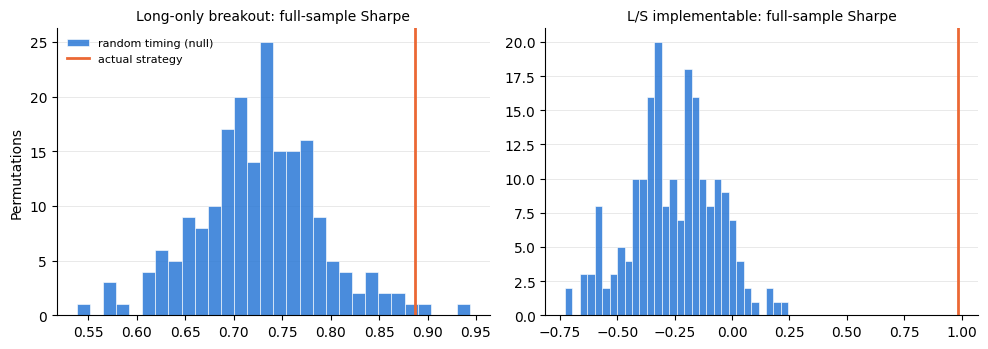

In [60]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (name, null) in zip(axs, perm.items()):
    ax.hist(null, bins=30, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.5, label="random timing (null)")
    ax.axvline(perm_table.loc[name, "observed Sharpe"], color=ORANGE, lw=2, label="actual strategy")
    ax.set_title(f"{name}: full-sample Sharpe", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
    ax.set_axisbelow(True)
axs[0].set_ylabel("Permutations")
axs[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "permutation_test.png", dpi=130)
plt.show()

The **L/S** book beats all 200 timing-shuffled versions (p ≈ 0.005, the floor). With random timing the same structure *loses* money, so the edge comes from *when* it trades. The **long-only** book beats 197 of 200 (p ≈ 0.015). Its null sits much higher (Sharpe ≈ 0.73), because any long book of these stocks earns the equity premium, but breakout timing still adds a significant margin.

### 13c. Paired stationary block bootstrap (does the edge survive a different history?)

* Resample the 2006–2026 (or 2017–2026) daily history in **blocks** of random length (mean 20 days; the stationary bootstrap of Politis & Romano). Blocks keep volatility clustering and autocorrelation intact.
* The resample is **paired**: the same days are drawn for the strategy and the benchmark, so their common exposure to the market is preserved.
* In each of 2,000 resamples, compute the difference in Sharpe (or mean return) between the strategy and (i) the drifting equal-weight ASX 500, and (ii) the median of 200 random buy-and-hold portfolios (K matched) evaluated on the same resampled days.
* The 95% interval is the 2.5th–97.5th percentile of those differences. The two-sided p-value is twice the share of resamples on the wrong side of zero.

This is the Ledoit & Wolf (2008) approach to testing Sharpe-ratio differences.

In [61]:
def stationary_bootstrap_idx(T, B, mean_block, rng):
    idx = np.empty((B, T), dtype=np.int64)
    idx[:, 0] = rng.integers(0, T, B)
    jump = rng.random((B, T)) < 1 / mean_block
    fresh = rng.integers(0, T, (B, T))
    for t in range(1, T):
        idx[:, t] = np.where(jump[:, t], fresh[:, t], (idx[:, t - 1] + 1) % T)
    return idx


def ann_sharpe(x, axis=0):
    return x.mean(axis) / x.std(axis) * np.sqrt(TRADING_DAYS)


B, BLOCK, N_RAND = 2000, 20, 200
brng = np.random.default_rng(11)
boot_rows = {}
for wname, start in WINDOWS.items():
    r_win = ret0.loc[start:]
    pool = np.flatnonzero(df["member"].loc[start:].iloc[0].values)
    growth = np.cumprod(1 + r_win.values, axis=0)
    picks = np.array([brng.choice(pool, k_match, replace=False) for _ in range(N_RAND)])
    value = growth[:, picks].mean(axis=2)
    rand = np.vstack([value[:1] - 1, value[1:] / value[:-1] - 1])     # T x N_RAND random B&H daily returns
    e = ew.loc[start:].values
    idx = stationary_bootstrap_idx(len(r_win), B, BLOCK, brng)
    for sname in ["Long-only breakout", "L/S implementable"]:
        x = mc_strats[sname].loc[start:].values
        diffs = {"ΔSharpe vs EW ASX 500": [], "ΔSharpe vs median random B&H": [], "Δann. return vs median random B&H": []}
        for row in idx:
            xs, rs = x[row], rand[row]
            sx = ann_sharpe(xs)
            diffs["ΔSharpe vs EW ASX 500"].append(sx - ann_sharpe(e[row]))
            diffs["ΔSharpe vs median random B&H"].append(sx - np.median(ann_sharpe(rs)))
            diffs["Δann. return vs median random B&H"].append((xs.mean() - np.median(rs.mean(0))) * TRADING_DAYS)
        observed = {"ΔSharpe vs EW ASX 500": ann_sharpe(x) - ann_sharpe(e),
                    "ΔSharpe vs median random B&H": ann_sharpe(x) - np.median(ann_sharpe(rand)),
                    "Δann. return vs median random B&H": (x.mean() - np.median(rand.mean(0))) * TRADING_DAYS}
        for test, arr in diffs.items():
            arr = np.array(arr)
            boot_rows[(wname, sname, test)] = {
                "observed": observed[test], "ci_low": np.percentile(arr, 2.5), "ci_high": np.percentile(arr, 97.5),
                "p_value": max(2 * min((arr <= 0).mean(), (arr >= 0).mean()), 1 / B)}
boot = pd.DataFrame(boot_rows).T
boot.to_csv(RESULTS / "11c_block_bootstrap.csv")
boot

observed  ci_low  ci_high  p_value
FULL 2006- Long-only breakout ΔSharpe vs EW ASX 500                 0.481   0.318    0.659    0.001
                              ΔSharpe vs median random B&H          0.325   0.100    0.553    0.004
                              Δann. return vs median random B&H     0.074   0.033    0.117    0.001
           L/S implementable  ΔSharpe vs EW ASX 500                 0.581  -0.080    1.220    0.090
                              ΔSharpe vs median random B&H          0.425  -0.277    1.080    0.237
                              Δann. return vs median random B&H    -0.015  -0.104    0.079    0.740
OOS 2017-  Long-only breakout ΔSharpe vs EW ASX 500                 0.497   0.310    0.705    0.001
                              ΔSharpe vs median random B&H          0.418   0.164    0.662    0.001
                              Δann. return vs median random B&H     0.093   0.042    0.143    0.001
           L/S implementable  ΔSharpe vs EW ASX 500                 0.277  -0.530    1.072    0.514
                              ΔSharpe vs median random B&H          0.198  -0.683    1.025    0.681
                              Δann. return vs median random B&H    -0.037  -0.152    0.083    0.536

**Reading the bootstrap**
* **Long-only:** the higher Sharpe *and* the higher return are significant in both windows; the intervals sit well above zero.
* **L/S:** its Sharpe is higher than buy-and-hold's, but over 9–20 years the interval for the *difference* includes zero, so it is **not** statistically different. Two Sharpe ratios, each estimated with a standard error of about 1/√years, are hard to tell apart.
* This does not contradict the significant L/S alpha in section 7. Alpha asks whether the strategy's mean return is above zero after removing market exposure: L/S alpha t ≈ 4 full-sample. The bootstrap asks whether its Sharpe beats a buy-and-hold Sharpe, a harder comparison because buy-and-hold also has a positive Sharpe.

### 13d. Deflated Sharpe ratio (correcting for the search)

The spec was chosen as the best of about 35 in-sample trials (sections 4–6). Even with no real edge, the best of 35 noisy Sharpe ratios would look good. The **deflated Sharpe ratio** (Bailey & López de Prado, 2014) raises the hurdle to the Sharpe you would *expect* from the best of N worthless trials, then asks how likely the observed Sharpe is to beat it, adjusting for skew and fat tails.

$$SR_0 = \sqrt{V[\widehat{SR}_n]}\left[(1-\gamma)\,\Phi^{-1}\!\left(1-\tfrac{1}{N}\right) + \gamma\,\Phi^{-1}\!\left(1-\tfrac{1}{Ne}\right)\right],\qquad
DSR = \Phi\!\left(\frac{(\widehat{SR}-SR_0)\sqrt{T-1}}{\sqrt{1-\hat\gamma_3\widehat{SR}+\tfrac{\hat\gamma_4-1}{4}\widehat{SR}^2}}\right)$$

$V$ is the variance of the trial Sharpe ratios, γ ≈ 0.5772 (the Euler–Mascheroni constant), and $\hat\gamma_3, \hat\gamma_4$ are the skew and kurtosis of daily returns. A DSR above 0.95 means significant at 5% after correcting for the search.

The out-of-sample period involved no search, so there the plain **probabilistic Sharpe ratio** (PSR, with hurdle $SR_0 = 0$) is the right test.

In [62]:
from scipy.stats import kurtosis, norm, skew


def psr(r, sr0_daily=0.0):
    r = r.dropna()
    sr = r.mean() / r.std()
    g3, g4 = skew(r), kurtosis(r, fisher=False)
    z = (sr - sr0_daily) * np.sqrt(len(r) - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)
    return norm.cdf(z)


def sr0_hurdle(trial_sharpes_ann, n_trials):
    v = np.var(np.asarray(trial_sharpes_ann) / np.sqrt(TRADING_DAYS), ddof=1)
    em = 0.5772156649
    return np.sqrt(v) * ((1 - em) * norm.ppf(1 - 1 / n_trials) + em * norm.ppf(1 - 1 / (n_trials * np.e)))


trials = np.r_[horizon.xs("IS", level="period")["sharpe"].values, exit_grid["sharpe"].values,
               vol_table.xs("IS", level=1)["sharpe"].values]
chosen_is = bts["Research L/S (all 500)"]["net"].loc[IS]     # the book the IS choices were made on
dsr_rows = {}
for label, tr in [("all 35 trials", trials), ("plausible trials only (Sharpe > -0.6)", trials[trials > -0.6])]:
    h = sr0_hurdle(tr, len(trials))
    dsr_rows[f"IS selection, {label}"] = {"Sharpe": stats(chosen_is)["sharpe"], "hurdle Sharpe": h * np.sqrt(TRADING_DAYS),
                                          "probability": psr(chosen_is, h)}
for name, sr in [("Research L/S (all 500)", bts["Research L/S (all 500)"]["net"]),
                 ("Implementable L/S (shorts top 200)", r_impl), ("Long-only", bts["Long-only"]["net"])]:
    dsr_rows[f"OOS PSR, {name}"] = {"Sharpe": stats(sr.loc[OOS])["sharpe"], "hurdle Sharpe": 0.0, "probability": psr(sr.loc[OOS])}
dsr = pd.DataFrame(dsr_rows).T
dsr.to_csv(RESULTS / "11d_deflated_sharpe.csv")
dsr

,Sharpe,hurdle Sharpe,probability
"IS selection, all 35 trials",1.507,7.495,0.000
"IS selection, plausible trials only (Sharpe > -0.6)",1.507,0.967,0.961
"OOS PSR, Research L/S (all 500)",1.495,0.000,1.000
"OOS PSR, Implementable L/S (shorts top 200)",0.763,0.000,0.991
"OOS PSR, Long-only",0.983,0.000,0.999


**Reading the deflated Sharpe**
* **With all 35 trials, the hurdle explodes** (Sharpe ≈ 7–9) and nothing could pass. The formula treats the spread of trial Sharpes as noise, but most of the spread here is the *deliberate* horizon sweep: the 5-day channel is −14 because short horizons reverse, not because of bad luck. That makes this version far too harsh.
* **With only plausible trials**, the in-sample Sharpe of 1.5 clears a hurdle of about 0.97 with probability about 0.96. That is just significant at 5%, so it is **borderline**: the in-sample result alone is weak evidence, and the verdict depends on which trials you count.
* **Out-of-sample**, where no search took place, the Sharpe ratios are significantly above zero (PSR ≥ 0.98 for all three books). The out-of-sample test is the real evidence.

### Summary of the tests

In [63]:
def pick(table, key, col="p_value"):
    return table.loc[key, col]

summary_tests = pd.DataFrame({
    "Long-only breakout": {
        "MC: Sharpe > random B&H (OOS)": mc_p.loc[("OOS 2017-", "Long-only breakout"), "p_sharpe"],
        "Permutation: timing matters (full)": perm_table.loc["Long-only breakout", "p-value"],
        "Bootstrap: ΔSharpe vs random B&H (OOS)": boot.loc[("OOS 2017-", "Long-only breakout", "ΔSharpe vs median random B&H"), "p_value"],
        "Bootstrap: Δreturn vs random B&H (OOS)": boot.loc[("OOS 2017-", "Long-only breakout", "Δann. return vs median random B&H"), "p_value"],
        "OOS Sharpe > 0 (1 - PSR)": 1 - dsr.loc["OOS PSR, Long-only", "probability"],
    },
    "L/S implementable": {
        "MC: Sharpe > random B&H (OOS)": mc_p.loc[("OOS 2017-", "L/S implementable"), "p_sharpe"],
        "Permutation: timing matters (full)": perm_table.loc["L/S implementable", "p-value"],
        "Bootstrap: ΔSharpe vs random B&H (OOS)": boot.loc[("OOS 2017-", "L/S implementable", "ΔSharpe vs median random B&H"), "p_value"],
        "Bootstrap: Δreturn vs random B&H (OOS)": boot.loc[("OOS 2017-", "L/S implementable", "Δann. return vs median random B&H"), "p_value"],
        "OOS Sharpe > 0 (1 - PSR)": 1 - dsr.loc["OOS PSR, Implementable L/S (shorts top 200)", "probability"],
    },
})
summary_tests.to_csv(RESULTS / "11_significance_summary.csv")
summary_tests.style.format("{:.3f}").map(lambda v: "font-weight: bold" if v < 0.05 else "")

,Long-only breakout,L/S implementable
MC: Sharpe > random B&H (OOS),0.001,0.001
Permutation: timing matters (full),0.015,0.005
Bootstrap: ΔSharpe vs random B&H (OOS),0.001,0.681
Bootstrap: Δreturn vs random B&H (OOS),0.001,0.536
OOS Sharpe > 0 (1 - PSR),0.001,0.009


Bold = significant at 5% (smaller p-values are stronger evidence).

## 14. Removing beta (the WSQ regression approach)

The course approach regresses returns on a benchmark, $r_t = \alpha + \beta\, r^{mkt}_t + \varepsilon_t$, and keeps what is left once market exposure is taken out. Here that can be applied at two levels.

1. **At the portfolio level (hedging).** Run the long-only breakout book and short the ASX 200 against it in proportion to its beta. In practice this is done with SPI 200 index futures, which are cheap and easy to short. This is an alternative way to make the book market-neutral **without shorting individual small caps**, which is the hard part on the ASX.
2. **At the signal level (residual momentum).** Strip each stock's market component out of its returns first, then look for breakouts in what remains. A stock then "breaks out" only when it outperforms what the market alone explains. Blitz, Huij & Martens (2011) find that residual momentum has fewer crashes than plain momentum.

The alpha regressions in sections 7 and 10 already remove beta when *measuring* performance. The question here is whether removing it when *trading* helps.

### 14a. Hedging the long-only book with the ASX 200

* Each day the hedge ratio is the long book's beta to the ASX 200 over the previous 126 days (6 months), using information up to yesterday only.
* The hedge return is $-\beta_{t-1}\, r^{ASX200}_t$, with 2 bps charged on changes in the hedge ratio.
* ^AXJO is a price index, so futures roll and carry are ignored; that is a simplification.

In [64]:
lo = bts["Long-only"]["net"]
m = axjo.fillna(0.0)
win = 126
cov = (lo * m).rolling(win, min_periods=60).mean() - lo.rolling(win, min_periods=60).mean() * m.rolling(win, min_periods=60).mean()
hedge_beta = (cov / m.rolling(win, min_periods=60).var()).shift(1).fillna(0.9)
lo_hedged = lo - hedge_beta * m - hedge_beta.diff().abs().fillna(0) * 2e-4

hedge_bts = {"Long-only (unhedged)": lo, "Long-only, ASX 200 beta hedge": lo_hedged,
             "Implementable L/S (shorts top 200)": r_impl}
hedge_table = pd.DataFrame({(name, per): pd.concat([stats(sr.loc[sl], ew), stats(sr.loc[sl], axjo)[["beta"]].rename({"beta": "beta_axjo"})])
                            for name, sr in hedge_bts.items() for per, sl in [("IS", IS), ("OOS", OOS)]}).T
hedge_table.to_csv(RESULTS / "12a_beta_hedge.csv")
hedge_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta_axjo"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  beta_axjo
Long-only (unhedged)               IS     0.146    0.184   0.796  -0.603  0.092    3.804      0.708
                                   OOS    0.193    0.196   0.983  -0.441  0.102    5.421      0.928
Long-only, ASX 200 beta hedge      IS     0.140    0.129   1.079  -0.433  0.120    3.608     -0.036
                                   OOS    0.143    0.138   1.032  -0.190  0.103    3.163     -0.021
Implementable L/S (shorts top 200) IS     0.094    0.079   1.194  -0.205  0.093    3.453     -0.079
                                   OOS    0.063    0.082   0.763  -0.115  0.054    2.172     -0.084

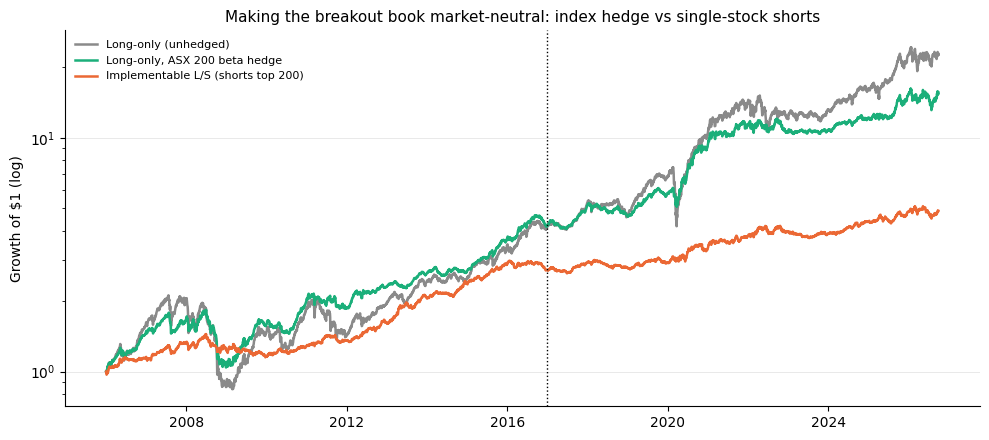

In [65]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for (name, sr), c in zip(hedge_bts.items(), [GREY, AQUA, ORANGE]):
    ax.plot((1 + sr.loc["2006":]).cumprod(), color=c, lw=1.8, label=name)
ax.axvline(pd.Timestamp("2017-01-01"), color="k", ls=":", lw=1)
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log)")
ax.set_title("Making the breakout book market-neutral: index hedge vs single-stock shorts", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "beta_hedge.png", dpi=130)
plt.show()

The hedge does what the regression promises: beta drops from 0.7–0.9 to about 0, volatility falls by about a third, and alpha is preserved. Out-of-sample, the hedged long book has a higher Sharpe than the implementable L/S book, a −19% drawdown, and needs only index futures to short.

On in-sample results the L/S book was slightly better (Sharpe 1.19 vs 1.08), so by the research rule it stays the primary strategy. The hedged long book is a credible implementable alternative, and arguably a more practical one. Its hedge is large-cap while its longs lean small-cap, so it still carries a size tilt. That mismatch showed up in 2008: the small-cap longs fell far more than the ASX 200 hedge offset, so the hedged book's in-sample drawdown is still −43%, against −21% for the L/S book. An index hedge removes *market* risk, not small-cap crash risk.

### 14b. Residual breakouts (signal-level beta removal)

* For each stock, regress its daily returns on the ASX 200 over a rolling 252-day window to get $\beta_{i,t}$ (using data up to yesterday only).
* Residual return: $\varepsilon_{i,t} = r_{i,t} - \beta_{i,t-1}\, r^{ASX200}_t$. Cumulating the residuals gives a "residual price".
* Apply the same breakout rules (N=250, M=125) to the residual price. There is no residual high or low, so channels use closing values, and the plain-price version is re-run on closes too so the comparison is like for like.

In [66]:
R, mret = df["ret"], axjo.reindex(df["ret"].index)
W = 252
mean_m = mret.rolling(W, min_periods=126).mean()
cov_im = R.mul(mret, axis=0).rolling(W, min_periods=126).mean() - R.rolling(W, min_periods=126).mean().mul(mean_m, axis=0)
beta_i = cov_im.div(mret.rolling(W, min_periods=126).var(), axis=0).shift(1)
resid_px = (1 + (R - beta_i.mul(mret, axis=0)).fillna(0)).cumprod().where(df["adj"].notna())


def donchian_close(px, n, m, member):
    up_n, lo_n = px.rolling(n, min_periods=n).max().shift(1), px.rolling(n, min_periods=n).min().shift(1)
    up_m, lo_m = px.rolling(m, min_periods=m).max().shift(1), px.rolling(m, min_periods=m).min().shift(1)

    def state(enter, leave):
        st = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
        return st.mask(leave | ~member, 0.0).mask(enter & member, 1.0).ffill().fillna(0.0)

    return state(px > up_n, px < lo_m) - state(px < lo_n, px > up_m)


resid_rows = {}
for label, px in [("price breakout (close-based)", df["adj"]), ("residual breakout", resid_px)]:
    sc = donchian_close(px, N, M, df["member"])
    books = {"L/S implementable": (sc.where((sc > 0) | top200, 0.0), "neutral"),
             "L/S all 500": (sc, "neutral"), "Long-only": (sc, "long")}
    for book, (sig, sch) in books.items():
        net = backtest_drift(sig, df, sch, 20, 2)["net"]
        for per, sl in [("IS", IS), ("OOS", OOS)]:
            st = stats(net.loc[sl], ew)
            resid_rows[(book, label, per)] = st
        resid_rows[(book, label, "2009 return")] = pd.Series({"ann_ret": (1 + net.loc["2009"]).prod() - 1})
resid_table = pd.DataFrame(resid_rows).T
resid_table.to_csv(RESULTS / "12b_residual_breakout.csv")
resid_table.loc[(slice(None), slice(None), ["IS", "OOS"]), ["sharpe", "max_dd", "alpha", "alpha_t"]].unstack(1)

sharpe                                         max_dd                                          alpha                                        alpha_t  \
                      price breakout (close-based) residual breakout price breakout (close-based) residual breakout price breakout (close-based) residual breakout price breakout (close-based)   
L/S all 500       IS                         1.418             1.297                       -0.156            -0.229                        0.097             0.079                        4.194   
                  OOS                        1.530             1.434                       -0.086            -0.088                        0.097             0.085                        4.224   
L/S implementable IS                         1.200             1.006                       -0.193            -0.263                        0.095             0.070                        3.628   
                  OOS                        0.758             0.634                       -0.131            -0.122                        0.054             0.040                        2.133   
Long-only         IS                         0.781             0.845                       -0.586            -0.597                        0.088             0.098                        3.654   
                  OOS                        0.987             0.965                       -0.436            -0.448                        0.104             0.100                        5.198   

                                         
                      residual breakout  
L/S all 500       IS              3.613  
                  OOS             3.815  
L/S implementable IS              2.910  
                  OOS             1.644  
Long-only         IS              4.563  
                  OOS             5.038

**Residual breakouts do not help here.** For both long/short books they are worse in-sample (which is enough to reject them under the research rule) and worse out-of-sample. Contrary to the residual-momentum literature, they also lose *more* in the 2009 momentum crash (see `results/12b_residual_breakout.csv`). For the long-only book the residual version is slightly better in-sample (Sharpe 0.85 vs 0.78) and slightly worse out-of-sample, so there is no real difference.

A likely reason: ASX small caps have low, unstable betas to the ASX 200, which is dominated by banks and big miners. The estimated market component is small and noisy, so subtracting it adds estimation error without removing much common risk. A sector or mining-index factor might work better than the broad index.

**Verdict on removing beta**
* **When measuring performance: yes.** That is the alpha regression, already used throughout.
* **When building the portfolio: worthwhile.** Hedging the long book with index futures gives a market-neutral strategy without single-stock shorts, and performed best out-of-sample.
* **When building the signal: not worthwhile here.** Residual breakouts were worse in-sample and out-of-sample.

## 15. Conclusions

In [67]:
summary = final.loc[(slice(None), ["IS", "OOS"]), ["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta_axjo"]]
summary.style.format({"ann_ret": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}",
                      "alpha": "{:.1%}", "alpha_t": "{:.1f}", "beta_axjo": "{:.2f}"})

,,ann_ret,ann_vol,sharpe,max_dd,alpha,alpha_t,beta_axjo
Research L/S (all 500),IS,10.5%,7.0%,1.51,-18.2%,10.1%,4.4,0.02
Implementable L/S (shorts top 200),IS,9.4%,7.9%,1.19,-20.5%,9.3%,3.5,-0.08
Long-only,IS,14.6%,18.4%,0.80,-60.3%,9.2%,3.8,0.71
"Implementable, 10% vol target",IS,12.2%,10.7%,1.14,-23.4%,12.0%,3.3,-0.09
Research L/S (all 500),OOS,10.3%,6.9%,1.50,-8.6%,9.2%,4.1,0.02
Implementable L/S (shorts top 200),OOS,6.3%,8.2%,0.76,-11.5%,5.4%,2.2,-0.08
Long-only,OOS,19.3%,19.6%,0.98,-44.1%,10.2%,5.4,0.93
"Implementable, 10% vol target",OOS,7.9%,10.6%,0.75,-17.3%,6.9%,2.1,-0.10


**Findings**
1. **Horizon decides the sign.** Breakouts of 50 days or less reverse; breakouts of 150–400 days persist. This is the brief's "short horizon → reversal, long horizon → momentum" pattern, on ASX data.
2. **A one-year channel works out-of-sample.** N=250 / M=125, chosen on 2006–2016 only, delivers a market-neutral OOS Sharpe of about 0.76 in its implementable form, with significant alpha that survives a size control.
3. **Execution:** trade the day after the breakout, not on the breakout close.
4. **Volume confirmation** points the right way (high-volume beats low-volume) but adds nothing over taking every breakout.
5. **vs buy-and-hold:** long-only breakouts beat random baskets on return, Sharpe and alpha, and the difference is statistically significant under every test (Monte Carlo, timing permutation, block bootstrap). The L/S book beats random baskets on Sharpe and drawdown and its breakout timing is significant (permutation p ≈ 0.005), but its Sharpe *advantage* over buy-and-hold is not significant once time-sampling noise is included.
6. **Search correction:** after deflating for the in-sample search, the in-sample Sharpe is only borderline significant (DSR ≈ 0.96 counting plausible trials, ≈ 0 if the dead short-horizon trials are counted). The once-only out-of-sample test is what establishes the edge.
7. **Removing beta:** hedging the long-only book with the ASX 200 gives a market-neutral book that needs no single-stock shorts and had the best out-of-sample Sharpe of the neutral variants. Building breakouts on beta-adjusted (residual) prices made results worse.

**Caveats**
* **Survivorship:** only today's listed companies are included. Missing failures would have paid the short leg; missing takeover targets would have paid the long leg. Alpha is measured against an equal-weight universe with the same bias, but a delisted-inclusive database is needed for a clean test.
* **Shorting:** borrow costs and availability are not modelled. The gap between the research and implementable books shows how much edge sits in hard-to-short names.
* **Capacity:** held names are thinly traded, so at 50 bps the OOS alpha loses significance.
* **Weighting:** there are no per-name, sector or liquidity caps, and each side gets 50% even when it holds few names.
* **Data:** Yahoo errors were filtered (notebook 01), but some may remain.

**Next steps:** survivorship-free data; a momentum-crash guard on the short leg (Daniel & Moskowitz); per-name and liquidity caps; a matched random-entry null that shifts each stock's signal in time, a tighter test than buy-and-hold.